# Floor-clip stress test, Stage A: where the floor lands under stain and scanner change (49 ROIs, no searches)

**Pre-registration.** This cell was written on 2026-10-08, before any smoke or full run of this notebook. It condenses
`TM_FLOOR_STRESS_STAGE_A_PLAN.md` (plan v3, judged converged after three review rounds). Where this cell and the plan
differ, the plan wins. Nothing below changes the arms, the metric or the decision rule. The reading is the last cell.

## Why

The floor clip `hem_c = max(hem, b)` with `b = b_otsu` is the adopted change (D3 amendment). `b_otsu` is the lower
3-class multi-Otsu threshold of the ROI's `hematoxylin_od`.

The floor-level ladder (`tm_floor_definition_49roi_6seed.ipynb`) gives P@10 at c = 0 / 0.5 / 1.0 / 1.5 / 2.0 × `b_otsu`
of 54.6 / 56.5 / 57.9 / 58.2 / 57.9.
- **Undershooting costs:** at 0.5× the clip loses about 40 % of its gain.
- **Overshooting does not cost in mean.**

The floor is estimated per image, so another lab's stain and scanner decide where it lands.

**The question:** under realistic stain and scanner changes, do the two decision-set estimators still land where the
searched ladder predicts no meaningful loss?

**It decides one thing:** whether Stage B (searches) runs, and on which perturbations. It runs **no template
searches**.

**What it cannot answer:**
- precision itself;
- whether the knee moves on a perturbed image;
- the rank-reshuffling effect of blur, JPEG and the gradient;
- real cross-scanner data;
- held-out ROIs;
- later loop rounds;
- chromatin od.

## Assumptions

- **A1. Equal tissue share clipped means the same position relative to the knee.**
  - This is exact for the clipped set under transforms monotone in `hem`. It does not hold for the TM response.
  - For blur, JPEG, eosin leak and RGB tone curves it is a proxy.
  - Stage A cannot test it.
- **A2. The perturbation strengths are a fixed judgment call.** They are not changed after any result.
- **A3. The per-ROI Macenko basis models the slide's stains.**
  - The residual is kept.
  - Negative concentrations are not scaled.
  - Pixels with any channel at 0 are copied unchanged by synthesis.
  - E×1.5 likely overstates eosin leak, because Macenko's E is the pinkest 1 %.
- **A4. Tissue masks.** The `c_eq` denominator uses the *original* tissue mask (gray ≤ 215). The tissue-only estimators
  use the perturbed image's own mask.

## Variants

`hem'` always comes from the production `hematoxylin_od`, computed on 1024-row blocks (bit-identity is gated in the
smoke run).

**Synthesis:**
- `OD = −log10((I + 1)/256)`.
- Macenko basis per ROI (β = 0.15, α = 1 %, 500,000 pixels), seeded with `default_rng([20261008, roi_index])`.
- `OD' = OD + (kH − 1)·max(cH, 0)·h + (kE − 1)·max(cE, 0)·e`.

| id | class | definition |
|---|---|---|
| `ID` | gate | full reconstruction `(C·[1, 1]) @ M.T + R` must re-encode bit for bit |
| `NULL2` | gate | `hem' = 2·hem` at channel level |
| `GAMMA`, `JPG95` | calibration (near-null) | equal-channel RGB gamma 1.1; JPEG quality 95, 4:2:0 |
| `H06`, `H14`, `E15` | realistic | kH = 0.6 / 1.4, kE = 1.5 |
| `CDN`, `CUP` | realistic | RGB LUTs `rint(12 + I·231/255)` and `clip(rint((I − 12)·255/231))` |
| `GAIN09`, `GAIN11` | realistic | all channels ×0.9 / ×1.1 |
| `WBR095`, `WBR105`, `WBB095`, `WBB105` | realistic | red or blue channel ×0.95 / ×1.05 |
| `BLUR`, `JPG`, `GRAD` | realistic | Gaussian σ = 1 px; JPEG quality 75, 4:2:0; OD × g, g linear 0.8 → 1.2 along the long axis |
| `SHIFT` | realistic, W128 only | original image; window moved 64 µm toward the offset (of 8) with the most glass |

## Estimators

Every estimator is the lower threshold of a 3-class multi-Otsu (nbins 256), as float32.

- **`b_otsu`** (decision set): over the whole ROI. The adopted estimator. The product keeps the default ROI size (user,
  2026-10-08).
- **`W128`** (decision set): over the click-centred `round(128/mpp) | 1` square, truncated at the ROI edge. Product-feasible
  and search-validated.
- **`TOTSU`** (descriptive, never searched): tissue pixels of the ROI.
- **`TW128`** (descriptive, never searched): tissue pixels of the W128 window. It is NaN below 5 % tissue.

## Metric

- `p' = count(hem'[T0] < float32(b')) / N_t`
- `c_eq = v0[min(round(p'·N_t), N_t − 1)] / b0`

Here `T0` is the original tissue mask, `v0` is the sorted original tissue values, and `b0` is the original `b_otsu`.
- For the ROI-wide estimators, the per-ROI value is the single value.
- For the window estimators, it is the median of the ROI's 6 clicks.

## Decision rule (fixed now)

**The ladder as a dose–response curve.** `L(c)` is piecewise-linear through (0, 0.545918), (0.25, 0.554422),
(0.5, 0.564966) and (1.0, 0.578912).
- `loss(c) = L(1.0) − L(c)` for c < 1. It is 0 for c ≥ 1, so no credit is given for overshoot.

For each realistic variant × decision-set estimator:
- **PL** is the mean of `loss(c_eq)` over the 294 click-landings, in P@10 points. A `b_otsu` value counts once per
  click of its ROI.
  - **PL fires at ≥ 0.25 pt.** That is a quarter of the 1-pt non-inferiority margin, about a uniform landing at 0.91.
- **OVER** fires if the median per-ROI `c_eq` is > 1.5, or any per-ROI `c_eq` is > 2.0.

**Outcome:**
- If anything fires, Stage B runs on the fired variants, plus `GRAD`, `BLUR`, `JPG` and the null control.
- If nothing fires, stop. There is no grey zone.

**Calibration gate (full run; reported only in the smoke run):**
- `NULL2`'s PL equals the unperturbed PL exactly.
- `GAMMA` and `JPG95` fire nothing.

## Gates (halt on failure)

1. **Configuration.** Production constants unchanged; skimage 0.24.0; nbins 256; every worker's thread pools at 1.
2. **Verbatim copies.** `roi_floors`, `window_floor` and `refine_template_box` (SHA-1 `21c43a20…`).
3. **Reproduction on this Mac.** `b0` and unperturbed W128 match the recorded floors within one bin; all recorded
   refinement boxes reproduce.
4. **`ID`** is bit-identical.
5. **Direction.** The slope of Δhem on the expected change lies in [0.9, 1.1] for H06, H14 and E15 (wherever ≥ 10,000
   pixels qualify), and H responds more than E in `rgb2hed`'s H column.
6. **`NULL2`.** Every floor is exactly 2×, and every `c_eq` and box is unchanged.
7. **`c_eq` self-consistency.** `|c_eq(c·b0) − c| < 0.01` on the ladder levels.
8. **Calibration** (full run).
9. **Smoke determinism.** N = 3 and N = 1 give identical outputs, and the blocked channel is bit-identical.

**Reported, not halted on:** Macenko angles against `floor_robustness/macenko.csv`, and the residual share.

**Runs.**
- **Smoke:** `TMSTRESS_SMOKE=1`, on 529 (the largest), 128 (clamp-heavy) and 401 (glass-rich). It writes `_smoke`
  outputs.
- **Full:** 49 ROIs, with N = min(16, floor(36 GB / smoke peak RSS)).
- Expected compute is about 2 min.

In [1]:
import hashlib
import inspect
import json
import os
import sys
import time
from multiprocessing import get_context

for _v in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'VECLIB_MAXIMUM_THREADS'):
    os.environ[_v] = '1'    # the spawn workers inherit these before they import numpy

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import skimage
import tifffile
from skimage.filters import threshold_multiotsu

sys.path.insert(0, '../..')
sys.path.insert(0, '.')
from midog_utils import production as prod
from midog_utils import template_match as tm
import tm_floor_stress_stageA_worker as W

pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 80)
pd.set_option('display.max_rows', 400)
pd.set_option('display.max_colwidth', 140)
NB_T0 = time.time()

# gate 1 -- the configuration
REFERENCE_CONFIG = dict(CHANNEL='hematoxylin_od', TM_METHOD=cv2.TM_CCOEFF, PEAK_MIN_DISTANCE=7, DEEP_FLOOR_Z=-1.5, MAX_PEAKS=100, OD_WINDOW=51)
assert all(getattr(prod, k) == v for k, v in REFERENCE_CONFIG.items()), 'gate 1: midog_utils.production no longer matches the configuration the ladder used'
assert skimage.__version__ == '0.24.0', f'gate 1: skimage {skimage.__version__}, the plan was checked on 0.24.0'
assert inspect.signature(threshold_multiotsu).parameters['nbins'].default == 256, 'gate 1: threshold_multiotsu no longer bins into 256'
assert tm.BASE_SIZE == 51 and W.WINDOW == 51, 'refine_template_box reads a 51 px window'

# runs
SMOKE = os.environ.get('TMSTRESS_SMOKE', '') == '1'
SMOKE_ROIS = ['529.tiff', '128.tiff', '401.tiff']     # the largest, the clamp-heavy and a glass-rich ROI
N_SMOKE = 3
N_MAX = 16
RSS_BUDGET_GB = 36.0                                 # of the 48 GB, leaving 12 GB for the OS and this kernel
SUFFIX = '_smoke' if SMOKE else ''

# the decision rule (cell 0), fixed before any run
DECISION_EST = ('b_otsu', 'W128')
DESCRIPTIVE_EST = ('TOTSU', 'TW128')
EST_ORDER = DECISION_EST + DESCRIPTIVE_EST
LADDER_C = (0.0, 0.25, 0.5, 1.0)
LADDER_P10 = (0.545918, 0.554422, 0.564966, 0.578912)   # P@10 at c x b_otsu, tm_floor_definition ladder.csv
PL_FIRE_PTS = 0.25
OVER_MEDIAN = 1.5
OVER_ANY = 2.0
STAGE_B_ALWAYS = ('GRAD', 'BLUR', 'JPG')                # plus the null control, if Stage B runs (FUTURE_IDEAS.md 4.1)
VAR_ORDER = list(W.VARIANT_CLASS)
REALISTIC = [v for v in VAR_ORDER if W.VARIANT_CLASS[v] == 'realistic']
CALIBRATION = [v for v in VAR_ORDER if W.VARIANT_CLASS[v] == 'calibration']
# gate tolerances
DIRECTION_BAND = (0.9, 1.1)
DIRECTION_MIN_N = 10_000
SELFCONS_TOL = 0.01
MACENKO_ANGLE_FLAG = dict(h=2.0, e=3.0)                 # degrees; reported, not halted on

# inputs and outputs
REC_PER_RUN = '../../results/tm_border_floor_49roi_6seed_per_run.csv'
FD = '../../results/tm_floor_definition_49roi_6seed'
INPUTS = {'rec_per_run': REC_PER_RUN, 'fd_floors': f'{FD}_floors.csv', 'fd_ladder': f'{FD}_ladder.csv', 'macenko': '../../floor_robustness/macenko.csv', 'worker': 'tm_floor_stress_stageA_worker.py', 'src_border_floor': 'tm_border_floor_49roi_6seed.ipynb', 'src_floor_definition': 'tm_floor_definition_49roi_6seed.ipynb', 'plan': '../../TM_FLOOR_STRESS_STAGE_A_PLAN.md'}
SMOKE_STEM = '../../results/tm_floor_stress_stageA_49roi_smoke'
OUT_STEM = f'../../results/tm_floor_stress_stageA_49roi{SUFFIX}'
OUT = {name: f'{OUT_STEM}_{name}.csv' for name in ('clicks', 'roi', 'summary', 'boxes', 'checks', 'decision', 'adversarial_log')}
assert not set(map(os.path.abspath, OUT.values())) & set(map(os.path.abspath, INPUTS.values())), 'an output path would overwrite an input'
if not SMOKE:
    existing = [p for p in OUT.values() if os.path.exists(p)]
    assert not existing, f'the full run never overwrites its outputs; these already exist: {existing}'

# the adversarial log: each concern is registered before any run and answered by the cell that tests it
ADV = {}


def adv(item, concern, test):
    """
        Register one adversarial concern and the test that answers it, before the test runs.

        item (str): a short key.
        concern (str): what could make the experiment fail or mislead.
        test (str): how this notebook tests it.

        Returns None.
    """
    ADV[item] = dict(item=item, concern=concern, test=test, result='', action='')


def adv_result(item, result, action):
    """
        Fill in one adversarial concern's result and the action taken.

        item (str): the key it was registered under.
        result (str): what the test found.
        action (str): what was done about it.

        Returns None.
    """
    assert item in ADV, f'{item} was never registered'
    ADV[item].update(result=result, action=action)


adv('a1_rank_changes', 'quantile matching (A1) hides rank changes from blur, JPEG, eosin leak and tone curves', 'stated as a limit in cell 0; rank-altering variants go to Stage B if it runs')
adv('noise_fires_rule', 'bin quantisation or noise could fire PL or OVER', 'PL averages 294 landings; the calibration variants GAMMA/JPG95 and NULL2 must fire nothing; bin width reported beside the top PL contributors')
adv('synthesis_wrong', 'the stain synthesis could be wrong while the identity gate passes', 'gate 5: direction slopes and the H/E label assert; ID covers only encoding')
adv('rule_after_pilot', 'the rule was revised after pilot data on 7 extreme ROIs', 'PL is anchored to the measured ladder and the NI margin; the pilot is reported in the plan, section 3.6')
adv('cross_machine', 'M5 vs Intel float drift could move the recorded floors', 'gate 3 within one multi-Otsu bin, with the exact float32-equal count reported')
adv('threads_memory', 'thread oversubscription or memory exhaustion', 'threadpool_info asserted at 1 in every worker; peak RSS measured on the largest ROI in the smoke run sets N')
adv('scheduling', 'worker scheduling could change results', 'per-ROI seeds; canonical sort; smoke determinism N = 3 vs N = 1')
adv('blocked_channel', 'the row-blocked channel could differ from the production whole-image call', 'smoke gate: bit-identity on the original and on H06 for every smoke ROI')

print(f'mode: {"SMOKE on " + ", ".join(SMOKE_ROIS) if SMOKE else "FULL, 49 ROIs"}')
print('outputs (all written at the end):', *OUT.values(), sep='\n  ')

mode: FULL, 49 ROIs
outputs (all written at the end):
  ../../results/tm_floor_stress_stageA_49roi_clicks.csv
  ../../results/tm_floor_stress_stageA_49roi_roi.csv
  ../../results/tm_floor_stress_stageA_49roi_summary.csv
  ../../results/tm_floor_stress_stageA_49roi_boxes.csv
  ../../results/tm_floor_stress_stageA_49roi_checks.csv
  ../../results/tm_floor_stress_stageA_49roi_decision.csv
  ../../results/tm_floor_stress_stageA_49roi_adversarial_log.csv


## Inputs, hashed

In [2]:
def sha256_12(path):
    """
        The first 12 hex digits of a file's SHA-256, so the inputs this notebook read are on record.

        path (str): the file to hash.

        Returns str: 12 hex characters.
    """
    with open(path, 'rb') as fh:
        return hashlib.sha256(fh.read()).hexdigest()[:12]


INPUT_SHA = {name: sha256_12(p) for name, p in INPUTS.items()}
for name, p in INPUTS.items():
    print(f'  {INPUT_SHA[name]}  {p}')

# the recorded clicks and refinement boxes (A0 rows of the border/floor run, tm_score)
REC = pd.read_csv(REC_PER_RUN, float_precision='round_trip')
CLK = REC[(REC['arm'] == 'A0') & (REC['rank_key'] == 'tm_score')][['subset', 'domain', 'file_name', 'seed_index', 'click_cx', 'click_cy', 'tcx', 'tcy', 'bs', 'mpp']].sort_values(['file_name', 'seed_index']).reset_index(drop=True)
ALL_FILES = sorted(CLK['file_name'].unique())
assert len(ALL_FILES) == 49 and len(CLK) == 294 and CLK.groupby('file_name').size().eq(6).all(), 'expected 49 ROIs x 6 clicks'
DOMAIN_OF = CLK.drop_duplicates('file_name').set_index('file_name')['domain']

# the recorded floors from the ladder run, read exactly
FDF = pd.read_csv(INPUTS['fd_floors'], float_precision='round_trip')
REC_B0 = FDF[FDF['arm'] == 'A3'].drop_duplicates('file_name').set_index('file_name')['b']
REC_W128 = FDF[FDF['arm'] == 'W128'].set_index(['file_name', 'seed_index'])['b']
assert set(REC_B0.index) == set(ALL_FILES) and len(REC_W128) == 294

# the ladder the decision rule interpolates must be the recorded one
lad = pd.read_csv(INPUTS['fd_ladder']).set_index('arm')
rec_ladder = tuple(round(float(lad.loc[a, 'P@10']), 6) for a in ('A1', 'L025', 'L050', 'A3'))
assert rec_ladder == LADDER_P10 and tuple(float(lad.loc[a, 'c']) for a in ('A1', 'L025', 'L050', 'A3')) == LADDER_C, f'the ladder changed: {rec_ladder}'

MAC = pd.read_csv(INPUTS['macenko']).set_index('file_name')
RUN_FILES = SMOKE_ROIS if SMOKE else ALL_FILES
print(f'\n{len(RUN_FILES)} ROIs this run; ladder P@10 {LADDER_P10} reproduces ladder.csv')

  ef7940000fec  ../../results/tm_border_floor_49roi_6seed_per_run.csv
  5f1bcc57c8b9  ../../results/tm_floor_definition_49roi_6seed_floors.csv
  4998f896bb40  ../../results/tm_floor_definition_49roi_6seed_ladder.csv
  5ddb0b64ada4  ../../floor_robustness/macenko.csv
  6998f6f46550  tm_floor_stress_stageA_worker.py
  9642fd221ebf  tm_border_floor_49roi_6seed.ipynb
  4bcbdf9b1e0d  tm_floor_definition_49roi_6seed.ipynb
  2d87ea2defdb  ../../TM_FLOOR_STRESS_STAGE_A_PLAN.md

49 ROIs this run; ladder P@10 (0.545918, 0.554422, 0.564966, 0.578912) reproduces ladder.csv


## The worker module: verbatim gates (gate 2)

In [3]:
def def_source(cell_src, name):
    """
        One top-level function's source as written in a notebook cell, from its def line to the next top-level line.

        cell_src (str): the cell's source.
        name (str): the function name.

        Returns str: the def block, trailing blank lines removed.
    """
    lines = cell_src.split('\n')
    start = next(i for i, ln in enumerate(lines) if ln.startswith(f'def {name}('))
    end = next((i for i in range(start + 1, len(lines)) if lines[i] and not lines[i][0].isspace()), len(lines))
    return '\n'.join(lines[start:end]).rstrip()


# gate 2 -- the three helpers in the worker are verbatim copies of their source cells
BF_CELLS = [''.join(c['source']) for c in json.load(open(INPUTS['src_border_floor']))['cells']]
FD_CELLS = [''.join(c['source']) for c in json.load(open(INPUTS['src_floor_definition']))['cells']]
for name, cells, idx in (('refine_template_box', BF_CELLS, 4), ('roi_floors', BF_CELLS, 8), ('window_floor', FD_CELLS, 9)):
    assert inspect.getsource(getattr(W, name)).rstrip() == def_source(cells[idx], name), f'gate 2: worker.{name} is not a verbatim copy'
assert hashlib.sha1(inspect.getsource(W.refine_template_box).encode()).hexdigest() == W.REFINE_SHA1 == '21c43a20db00dccf7ac3bab88aee423c345441b6', 'gate 2: refine_template_box is not the c767898 source'
c1 = BF_CELLS[1]
consts = c1[c1.index("# refine_template_box's constants"):c1.index('\n', c1.index('REFINE_SHA1 ='))]
assert consts in open(INPUTS['worker']).read(), "gate 2: refine_template_box's constants are not verbatim"
print(f'gate 2 held: refine_template_box (SHA-1 {W.REFINE_SHA1[:8]}), its constants, roi_floors and window_floor are verbatim; worker sha256 {INPUT_SHA["worker"]}')

gate 2 held: refine_template_box (SHA-1 21c43a20), its constants, roi_floors and window_floor are verbatim; worker sha256 6998f6f46550


## Tasks, largest ROI first

In [4]:
SUBSET_DIRS = {'original_14': '../../images/extra_valid', 'testing_35': '../../images/extra_valid/testing_set'}


def make_task(fn):
    """
        One ROI's task for the worker.

        fn (str): the ROI file name.

        Returns dict: file_name, path, mpp, roi_index (position in the sorted 49), clicks with their recorded boxes, n_px.
    """
    rows = CLK[CLK['file_name'] == fn]
    path = f"{SUBSET_DIRS[rows['subset'].iat[0]]}/{fn}"
    with tifffile.TiffFile(path) as tf:
        shape = tf.pages[0].shape
    clicks = [dict(seed_index=int(r.seed_index), click_cx=float(r.click_cx), click_cy=float(r.click_cy), tcx=int(r.tcx), tcy=int(r.tcy), bs=int(r.bs)) for r in rows.itertuples()]
    return dict(file_name=fn, path=path, mpp=float(rows['mpp'].iat[0]), roi_index=ALL_FILES.index(fn), clicks=clicks, n_px=int(shape[0] * shape[1]))


# largest ROI first (LPT), so the long tasks start at once and the short ones fill in
TASKS = sorted((make_task(fn) for fn in RUN_FILES), key=lambda t: (-t['n_px'], t['file_name']))
print(f"{len(TASKS)} tasks, largest first: {TASKS[0]['file_name']} ({TASKS[0]['n_px'] / 1e6:.1f} MP) ... {TASKS[-1]['file_name']} ({TASKS[-1]['n_px'] / 1e6:.1f} MP)")

49 tasks, largest first: 007.tiff (39.0 MP) ... 344.tiff (31.2 MP)


## The run: a spawn pool with every thread pool pinned to 1

The smoke run measures the peak memory per worker on the largest ROI, checks that the row-blocked channel equals the production whole-image call, and re-runs at N = 1 for the determinism gate. The full run sets N from the smoke peak.

In [5]:
def run_pool(tasks, n_workers, check_blocked):
    """
        Run the worker on every task in a spawn pool, largest ROI first.

        tasks (list[dict]): the ROI tasks, already in LPT order.
        n_workers (int): pool size.
        check_blocked (bool): also run the smoke-only blocked-channel bit-identity check.

        Returns tuple[list[dict], float]: the worker results (completion order) and the wall time in s.
    """
    t0 = time.time()
    results = []
    with get_context('spawn').Pool(n_workers, initializer=W.init_worker) as pool:
        for i, res in enumerate(pool.imap_unordered(W.run_roi, [dict(t, check_blocked=check_blocked) for t in tasks], chunksize=1)):
            results.append(res)
            print(f"[{i + 1}/{len(tasks)} {res['file_name']}] {res['timing']['total']:.1f} s in worker {res['pid']}, peak RSS {res['checks']['peak_rss_gb_work']:.2f} GB; {(time.time() - t0) / 60:.1f} min elapsed", flush=True)
    return results, time.time() - t0


if SMOKE:
    N_WORKERS = N_SMOKE
    RESULTS, WALL = run_pool(TASKS, N_SMOKE, True)
    print(f'smoke at N = {N_SMOKE}: {WALL:.0f} s wall')
    RESULTS_N1, WALL_N1 = run_pool(TASKS, 1, False)
    print(f'smoke at N = 1: {WALL_N1:.0f} s wall')
else:
    sm_checks = pd.read_csv(f'{SMOKE_STEM}_checks.csv')
    sm_dec = pd.read_csv(f'{SMOKE_STEM}_decision.csv').set_index('item')['result']
    assert set(SMOKE_ROIS) == set(sm_checks['file_name']), 'the smoke checks are not from the smoke ROIs'
    assert str(sm_dec['smoke determinism (N = 3 vs N = 1)']) == 'True' and str(sm_dec['smoke blocked channel bit-identical']) == 'True', 'the smoke run did not pass its gates'
    SMOKE_PEAK_GB = float(sm_checks['peak_rss_gb_work'].max())
    N_WORKERS = int(os.environ.get('TMSTRESS_N', '0')) or min(N_MAX, int(RSS_BUDGET_GB // SMOKE_PEAK_GB))
    print(f'smoke peak RSS {SMOKE_PEAK_GB:.2f} GB per worker -> N = {N_WORKERS}')
    RESULTS, WALL = run_pool(TASKS, N_WORKERS, False)
    print(f'full run at N = {N_WORKERS}: {WALL / 60:.1f} min wall; worker CPU {sum(r["timing"]["total"] for r in RESULTS) / 60:.1f} min')

smoke peak RSS 3.09 GB per worker -> N = 11


[1/49 401.tiff] 42.8 s in worker 27607, peak RSS 2.34 GB; 0.7 min elapsed


[2/49 403.tiff] 46.6 s in worker 27612, peak RSS 2.76 GB; 0.8 min elapsed


[3/49 364.tiff] 47.0 s in worker 27605, peak RSS 2.71 GB; 0.8 min elapsed


[4/49 007.tiff] 47.9 s in worker 27603, peak RSS 2.84 GB; 0.8 min elapsed


...

[46/49 322.tiff] 32.6 s in worker 27610, peak RSS 2.76 GB; 3.4 min elapsed


[47/49 339.tiff] 31.9 s in worker 27607, peak RSS 2.75 GB; 3.4 min elapsed


[48/49 343.tiff] 32.0 s in worker 27613, peak RSS 2.76 GB; 3.5 min elapsed


[49/49 344.tiff] 31.7 s in worker 27609, peak RSS 2.86 GB; 3.5 min elapsed


full run at N = 11: 3.5 min wall; worker CPU 35.0 min


## Landings, boxes and checks; smoke determinism (gate 9)

In [6]:
NONDETERMINISTIC = ('peak_rss_gb_work', 'threads', 'pid', 'blocked_n_diff_orig', 'blocked_n_diff_H06')


def assemble(results):
    """
        The worker results as three canonically sorted frames.

        results (list[dict]): worker results, in any order.

        Returns tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]: landings (one row per variant, estimator and click; ROI-wide estimators at seed_index -1), boxes, and per-ROI checks with timings.
    """
    var_rank = {v: i for i, v in enumerate(VAR_ORDER)}
    est_rank = {e: i for i, e in enumerate(EST_ORDER)}
    rows = pd.DataFrame([r for res in results for r in res['rows']])
    rows = rows.assign(var_class=rows['var'].map(W.VARIANT_CLASS), domain=rows['file_name'].map(DOMAIN_OF), _v=rows['var'].map(var_rank), _e=rows['est'].map(est_rank))
    rows = rows.sort_values(['file_name', '_v', '_e', 'seed_index'], kind='mergesort').drop(columns=['_v', '_e']).reset_index(drop=True)
    boxes = pd.DataFrame([b for res in results for b in res['boxes']])
    boxes = boxes.assign(_v=boxes['var'].map(var_rank)).sort_values(['file_name', '_v', 'seed_index'], kind='mergesort').drop(columns='_v').reset_index(drop=True)
    checks = pd.DataFrame([dict(res['checks'], pid=res['pid'], **{f't_{k}': v for k, v in res['timing'].items()}) for res in results])
    checks = checks.sort_values('file_name').reset_index(drop=True)
    return rows, boxes, checks


ROWS, BOXES, CHECKS = assemble(RESULTS)
CHECKS = CHECKS.assign(domain=CHECKS['file_name'].map(DOMAIN_OF))
assert len(ROWS) == len(RUN_FILES) * (len(W.VARIANT_CLASS) - 2) * (2 + 2 * 6) + len(RUN_FILES) * 6, f'unexpected landing count {len(ROWS)}'
assert len(BOXES) == len(RUN_FILES) * 6 * (len(W.IMAGE_VARIANTS) + 2)
print(f'{len(ROWS)} landings, {len(BOXES)} boxes, {len(CHECKS)} ROIs')

SMOKE_GATES = {}
if SMOKE:
    # gate 9 -- determinism: N = 3 and N = 1 give identical landings, boxes and deterministic checks
    r1, b1, c1 = assemble(RESULTS_N1)
    keep = [c for c in CHECKS.columns if c in c1.columns and not c.startswith('t_') and c not in NONDETERMINISTIC and c != 'domain']
    pd.testing.assert_frame_equal(ROWS.drop(columns=['var_class', 'domain']), r1.drop(columns=['var_class', 'domain']), check_exact=True)
    pd.testing.assert_frame_equal(BOXES, b1, check_exact=True)
    pd.testing.assert_frame_equal(CHECKS[keep], c1[keep], check_exact=True)
    SMOKE_GATES['smoke determinism (N = 3 vs N = 1)'] = True
    # the blocked channel is the production channel, bit for bit
    blocked_ok = bool((CHECKS['blocked_n_diff_orig'] == 0).all() and (CHECKS['blocked_n_diff_H06'] == 0).all())
    assert blocked_ok, f"smoke gate: the row-blocked channel differs from the whole-image call: {CHECKS[['file_name', 'blocked_n_diff_orig', 'blocked_n_diff_H06']].to_dict('records')}"
    SMOKE_GATES['smoke blocked channel bit-identical'] = True
    adv_result('scheduling', 'N = 3 and N = 1 give identical landings, boxes and checks', 'gate held')
    adv_result('blocked_channel', f"0 differing pixels on the original and H06 for {', '.join(CHECKS['file_name'])}", 'row-blocked channel adopted')
    print('gate 9 held: N = 3 and N = 1 identical; the row-blocked channel equals the whole-image call on every smoke ROI (original and H06)')

12642 landings, 5292 boxes, 49 ROIs


## Gates on the outputs (gates 1, 3-7, and the reported Macenko check)

In [7]:
GATES = {}

# gate 1 (workers) -- every pool in every worker reported one thread
bad_threads = CHECKS.loc[~CHECKS['threads'].str.split(';').apply(lambda ps: all(p.endswith(':1') for p in ps)), ['file_name', 'threads']]
assert bad_threads.empty, f'gate 1: unpinned thread pools: {bad_threads.to_dict("records")}'
GATES['gate 1: worker thread pools at 1'] = True
adv_result('threads_memory', f"pools {CHECKS['threads'].iat[0]}; peak RSS {CHECKS['peak_rss_gb_work'].max():.2f} GB per worker", 'N set from the smoke peak' if not SMOKE else 'this smoke peak sets N for the full run')

# gate 3 -- the original floors and boxes reproduce on this Mac
un = ROWS[ROWS['var'] == 'UNPERT']
g3 = CHECKS[['file_name', 'b0', 'b0_bin_width']].assign(rec=CHECKS['file_name'].map(REC_B0))
g3['abs_diff'] = (g3['b0'] - g3['rec']).abs()
g3['f32_equal'] = np.float32(g3['b0'].to_numpy()) == np.float32(g3['rec'].to_numpy())
assert (g3['abs_diff'] <= g3['b0_bin_width']).all(), f"gate 3: b0 differs from floors.csv by more than one bin: {g3[g3['abs_diff'] > g3['b0_bin_width']].to_dict('records')}"
w = un[un['est'] == 'W128'].assign(rec=lambda d: [REC_W128[(f, s)] for f, s in zip(d['file_name'], d['seed_index'])])
w = w.assign(abs_diff=(w['b'] - w['rec']).abs(), f32_equal=np.float32(w['b'].to_numpy()) == np.float32(w['rec'].to_numpy()))
assert (w['abs_diff'] <= w['bin_width']).all(), f"gate 3: unperturbed W128 differs from floors.csv by more than one window bin: {w[w['abs_diff'] > w['bin_width']][['file_name', 'seed_index', 'b', 'rec', 'bin_width']].to_dict('records')}"
ub = BOXES[BOXES['var'] == 'UNPERT']
assert ub['box_matches'].all(), f"gate 3: recorded refinement boxes not reproduced: {ub[~ub['box_matches']].to_dict('records')}"
GATES['gate 3: floors and boxes reproduce'] = True
adv_result('cross_machine', f"b0 float32-equal on {int(g3['f32_equal'].sum())}/{len(g3)} ROIs (max rel diff {float((g3['abs_diff'] / g3['rec']).max()):.1e}); W128 float32-equal on {int(w['f32_equal'].sum())}/{len(w)} clicks (max rel diff {float((w['abs_diff'] / w['rec']).max()):.1e}); all within one bin; boxes {int(ub['box_matches'].sum())}/{len(ub)}", 'gate held')
print(f"gate 3 held: b0 within one bin on all {len(g3)} ROIs ({int(g3['f32_equal'].sum())} float32-equal), W128 within one window bin on all {len(w)} clicks ({int(w['f32_equal'].sum())} float32-equal), {len(ub)}/{len(ub)} recorded boxes reproduced")

# gate 4 -- the identity synthesis re-encodes bit for bit
assert (CHECKS['id_n_diff'] == 0).all(), f"gate 4: ID changed pixels: {CHECKS.loc[CHECKS['id_n_diff'] > 0, ['file_name', 'id_n_diff']].to_dict('records')}"
GATES['gate 4: ID bit-identical'] = True

# gate 5 -- direction: the stain synthesis moves hem by the expected amount, along the right stain
assert CHECKS['label_ok'].all(), f"gate 5: E responds more than H in rgb2hed's H column on {CHECKS.loc[~CHECKS['label_ok'], 'file_name'].tolist()}"
dir_rows = []
for var in W.STAIN_K:
    for r in CHECKS.itertuples():
        slope, n = getattr(r, f'dir_slope_{var}'), getattr(r, f'dir_n_{var}')
        dir_rows.append(dict(file_name=r.file_name, var=var, slope=slope, r=getattr(r, f'dir_r_{var}'), n=n, tested=n >= DIRECTION_MIN_N, ok=(n < DIRECTION_MIN_N) or (DIRECTION_BAND[0] <= slope <= DIRECTION_BAND[1])))
DIRECTION = pd.DataFrame(dir_rows)
assert DIRECTION['ok'].all(), f"gate 5: direction slope outside {DIRECTION_BAND}: {DIRECTION[~DIRECTION['ok']].to_dict('records')}"
GATES['gate 5: direction slopes and H/E labels'] = True
print('gate 5 held: direction slope per variant (min / median / max over ROIs; ROIs below', DIRECTION_MIN_N, 'qualifying pixels untested):')
print(DIRECTION.groupby('var').agg(slope_min=('slope', 'min'), slope_median=('slope', 'median'), slope_max=('slope', 'max'), r_min=('r', 'min'), n_min=('n', 'min'), untested=('tested', lambda t: int((~t).sum()))).round(4).to_string())
adv_result('synthesis_wrong', f"slopes {DIRECTION['slope'].min():.3f}-{DIRECTION['slope'].max():.3f}; H/E labels correct on all ROIs", 'gate held')

# gate 6 -- NULL2: every floor exactly 2x, every c_eq and every box unchanged
key = ['file_name', 'est', 'seed_index']
n2 = ROWS[ROWS['var'] == 'NULL2'].set_index(key).sort_index()
u0 = un.set_index(key).sort_index()
both_nan = n2['b'].isna() & u0['b'].isna()
two_x = (np.float32(n2['b'].to_numpy()) == np.float32(2.0) * np.float32(u0['b'].to_numpy())) | both_nan.to_numpy()
same_c = (n2['c_eq'].to_numpy() == u0['c_eq'].to_numpy()) | (n2['c_eq'].isna() & u0['c_eq'].isna()).to_numpy()
assert two_x.all() and same_c.all(), f'gate 6: NULL2 is not exact on {int((~two_x).sum())} floors and {int((~same_c).sum())} c_eq values'
nb = BOXES[BOXES['var'] == 'NULL2'].set_index(['file_name', 'seed_index'])[['accepted', 'bs', 'tcx', 'tcy']]
assert nb.equals(ub.set_index(['file_name', 'seed_index'])[['accepted', 'bs', 'tcx', 'tcy']]), 'gate 6: NULL2 changed a refinement box'
GATES['gate 6: NULL2 exact'] = True

# gate 7 -- c_eq self-consistency on the ladder levels
sc = CHECKS[[c for c in CHECKS.columns if c.startswith('selfcons_')]]
dev = pd.DataFrame({c: (sc[c] - float(c.split('_')[1])).abs() for c in sc.columns})
assert (dev < SELFCONS_TOL).all().all() and ((CHECKS['selfcons_1'] >= 1.0) & (CHECKS['selfcons_1'] < 1.0 + SELFCONS_TOL)).all(), f'gate 7: c_eq self-consistency fails: max deviation {dev.max().to_dict()}'
GATES['gate 7: c_eq self-consistency'] = True
print(f'gates 4, 6, 7 held: ID bit-identical on all ROIs; NULL2 exact (floors 2x, c_eq and boxes unchanged); c_eq self-consistent to {float(dev.max().max()):.1e}')


def angle_deg(a, b):
    """
        The angle between two vectors, ignoring sign.

        a (np.ndarray): first vector.
        b (np.ndarray): second vector.

        Returns float: degrees.
    """
    return float(np.degrees(np.arccos(np.clip(abs(a @ b) / np.linalg.norm(a) / np.linalg.norm(b), -1, 1))))


# gate 10 (reported) -- the Macenko basis against floor_robustness/macenko.csv, and the residual share
mac_rows = []
for r in CHECKS.itertuples():
    h = np.array([r.h0, r.h1, r.h2])
    e = np.array([r.e0, r.e1, r.e2])
    mac_rows.append(dict(file_name=r.file_name, ang_h_vs_csv=angle_deg(h, np.array(json.loads(MAC.loc[r.file_name, 'h_est']))), ang_e_vs_csv=angle_deg(e, np.array(json.loads(MAC.loc[r.file_name, 'e_est']))), resid_share=r.resid_share, h_resp=r.h_resp, e_resp=r.e_resp, zero_px_share=r.zero_px_share))
MACENKO = pd.DataFrame(mac_rows)
mac_flag = MACENKO[(MACENKO['ang_h_vs_csv'] > MACENKO_ANGLE_FLAG['h']) | (MACENKO['ang_e_vs_csv'] > MACENKO_ANGLE_FLAG['e'])]
print(f"Macenko (reported): angle to macenko.csv max {MACENKO['ang_h_vs_csv'].max():.2f} deg (h), {MACENKO['ang_e_vs_csv'].max():.2f} deg (e); flagged ROIs: {mac_flag['file_name'].tolist() or 'none'}; residual share median {MACENKO['resid_share'].median():.3f} (max {MACENKO['resid_share'].max():.3f}); zero-channel pixels: {int((MACENKO['zero_px_share'] > 0).sum())} ROIs, max share {MACENKO['zero_px_share'].max():.4f}")

gate 3 held: b0 within one bin on all 49 ROIs (45 float32-equal), W128 within one window bin on all 294 clicks (261 float32-equal), 294/294 recorded boxes reproduced
gate 5 held: direction slope per variant (min / median / max over ROIs; ROIs below 10000 qualifying pixels untested):
     slope_min  slope_median  slope_max   r_min   n_min  untested
var                                                              
E15     0.9744        1.0046     1.0111  0.3007  643746         0
H06     1.0034        1.0081     1.0140  0.9992  637746         0
H14     1.0038        1.0096     1.0186  0.9979  714652         0
gates 4, 6, 7 held: ID bit-identical on all ROIs; NULL2 exact (floors 2x, c_eq and boxes unchanged); c_eq self-consistent to 7.6e-05
Macenko (reported): angle to macenko.csv max 0.32 deg (h), 0.41 deg (e); flagged ROIs: none; residual share median 0.036 (max 0.122); zero-channel pixels: 31 ROIs, max share 0.0092


## The decision, by the rule fixed in cell 0 (gate 8 first)

In [8]:
def loss_pts(c):
    """
        The P@10 the ladder predicts a landing costs: L(1) - L(c) below 1, piecewise-linear through the measured levels, and 0 at or above 1.

        c (array-like): equivalent levels c_eq.

        Returns np.ndarray: predicted loss in P@10 points (NaN where c is NaN).
    """
    c = np.asarray(c, dtype=float)
    loss = 100.0 * (LADDER_P10[-1] - np.interp(np.clip(c, 0.0, 1.0), LADDER_C, LADDER_P10))
    return np.where(np.isnan(c), np.nan, np.where(c >= 1.0, 0.0, loss))


def landings(var, est):
    """
        One variant and estimator's click-landings: ROI-wide values repeated for each of the ROI's clicks.

        var (str): the variant.
        est (str): the estimator.

        Returns pd.DataFrame: file_name, seed_index, c_eq, one row per click.
    """
    d = ROWS[(ROWS['var'] == var) & (ROWS['est'] == est)]
    if est in ('b_otsu', 'TOTSU'):
        d = CLK[CLK['file_name'].isin(RUN_FILES)][['file_name', 'seed_index']].merge(d[['file_name', 'c_eq']], on='file_name')
    return d[['file_name', 'seed_index', 'c_eq']].reset_index(drop=True)


def cell_stats(var, est):
    """
        PL, OVER and the per-ROI landing distribution for one variant and estimator.

        var (str): the variant.
        est (str): the estimator.

        Returns dict: n landings, NaN count, PL (pts), per-ROI median / 5th / 95th percentile / max, click share below 0.9, OVER and PL flags.
    """
    d = landings(var, est)
    roi = d.groupby('file_name')['c_eq'].median()
    pl = float(np.nanmean(loss_pts(d['c_eq'])))
    over = bool(roi.median() > OVER_MEDIAN or (roi > OVER_ANY).any())
    return dict(var=var, var_class=W.VARIANT_CLASS[var], est=est, n_landings=int(d['c_eq'].notna().sum()), n_nan=int(d['c_eq'].isna().sum()), PL_pts=pl, roi_median=float(roi.median()), roi_p05=float(roi.quantile(0.05)), roi_p95=float(roi.quantile(0.95)), roi_min=float(roi.min()), roi_max=float(roi.max()), click_share_below_0p9=float((d['c_eq'] < 0.9).mean()), pl_fires=bool(pl >= PL_FIRE_PTS), over_fires=over)


cells = [(v, e) for v in VAR_ORDER if v != 'ID' for e in EST_ORDER if not (v == 'SHIFT' and e != 'W128')]
SUMMARY = pd.DataFrame([cell_stats(v, e) for v, e in cells])
SUMMARY['decides'] = SUMMARY['var_class'].eq('realistic') & SUMMARY['est'].isin(DECISION_EST)
SUMMARY['fires'] = SUMMARY['decides'] & (SUMMARY['pl_fires'] | SUMMARY['over_fires'])
S = SUMMARY.set_index(['var', 'est'])

# gate 8 -- calibration: NULL2 equals the unperturbed PL exactly; GAMMA and JPG95 fire nothing
cal_rows = []
for est in DECISION_EST:
    cal_rows.append(dict(item=f'NULL2 PL == UNPERT PL ({est})', ok=S.loc[('NULL2', est), 'PL_pts'] == S.loc[('UNPERT', est), 'PL_pts'], value=S.loc[('NULL2', est), 'PL_pts']))
    for var in CALIBRATION:
        cal_rows.append(dict(item=f'{var} fires nothing ({est})', ok=not (S.loc[(var, est), 'pl_fires'] or S.loc[(var, est), 'over_fires']), value=S.loc[(var, est), 'PL_pts']))
CALIB = pd.DataFrame(cal_rows)
print('calibration (gate 8):')
print(CALIB.to_string(index=False, float_format=lambda v: f'{v:.4f}'))
if SMOKE:
    print('[smoke: reported only, on 3 extreme ROIs]')
else:
    assert CALIB['ok'].all(), f"gate 8: the rule is miscalibrated: {CALIB[~CALIB['ok']].to_dict('records')}"
    GATES['gate 8: calibration'] = True

FIRED = SUMMARY[SUMMARY['fires']]
FIRED_VARS = [v for v in VAR_ORDER if v in set(FIRED['var'])]
STAGE_B = FIRED_VARS + [v for v in STAGE_B_ALWAYS if v not in FIRED_VARS] if FIRED_VARS else []
print('\nthe decision cells (realistic variant x decision-set estimator): PL in P@10 points, per-ROI c_eq')
show = ['var', 'est', 'PL_pts', 'roi_median', 'roi_p05', 'roi_min', 'roi_max', 'click_share_below_0p9', 'pl_fires', 'over_fires', 'fires']
print(SUMMARY[SUMMARY['decides']][show].to_string(index=False, float_format=lambda v: f'{v:.3f}'))
print(f"\nunperturbed reference: PL b_otsu {S.loc[('UNPERT', 'b_otsu'), 'PL_pts']:.3f}, W128 {S.loc[('UNPERT', 'W128'), 'PL_pts']:.3f} (the searched W128 arm measured +0.24 pt [-0.10, +0.58] against A3)")
print(f"\nfired: {FIRED[['var', 'est']].to_records(index=False).tolist() or 'nothing'}")
print(f"Stage B: {'runs on ' + ', '.join(STAGE_B) + ' + the null control' if STAGE_B else 'NOT needed (nothing fired)'}" + ('   [SMOKE RUN: not a result]' if SMOKE else ''))
adv_result('noise_fires_rule', '; '.join(f"{r.item}: {r.value:.3f} ({'ok' if r.ok else 'FAILS'})" for r in CALIB.itertuples()), 'gate 8 ' + ('reported (smoke)' if SMOKE else 'held'))

calibration (gate 8):
                          item   ok  value
NULL2 PL == UNPERT PL (b_otsu) True 0.0000
  GAMMA fires nothing (b_otsu) True 0.0566
  JPG95 fires nothing (b_otsu) True 0.0726
  NULL2 PL == UNPERT PL (W128) True 0.0559
    GAMMA fires nothing (W128) True 0.0581
    JPG95 fires nothing (W128) True 0.0811

the decision cells (realistic variant x decision-set estimator): PL in P@10 points, per-ROI c_eq
   var    est  PL_pts  roi_median  roi_p05  roi_min  roi_max  click_share_below_0p9  pl_fires  over_fires  fires
   H06 b_otsu   0.411       0.858    0.692    0.675    1.296                  0.592      True       False   True
   H06   W128   0.333       0.910    0.730    0.663    1.468                  0.510      True       False   True
   H14 b_otsu   0.009       1.066    0.973    0.928    1.269                  0.000     False       False  False
   H14   W128   0.024       1.103    1.012    0.963    1.497                  0.027     False       False  False
   E15 b_otsu 

## Descriptive: never used for the decision

In [9]:
# the whole summary, including the calibration rows and the descriptive estimators
print('every variant x estimator (PL in P@10 points; per-ROI c_eq quantiles; TOTSU and TW128 descriptive):')
print(SUMMARY.drop(columns=['var_class']).to_string(index=False, float_format=lambda v: f'{v:.3f}'))

# the ROIs that contribute most to each fired cell's PL, with the floor's bin width in c_eq units
contrib_rows = []
for r in FIRED.itertuples():
    d = landings(r.var, r.est).assign(loss=lambda x: loss_pts(x['c_eq']))
    per = d.groupby('file_name').agg(c_eq_median=('c_eq', 'median'), loss_sum=('loss', 'sum'))
    per['share_of_PL'] = per['loss_sum'] / per['loss_sum'].sum() if per['loss_sum'].sum() > 0 else 0.0
    src = ROWS[(ROWS['var'] == r.var) & (ROWS['est'] == r.est)].groupby('file_name').agg(b=('b', 'median'), bin_width=('bin_width', 'median'))
    per = per.join(src)
    per['bin_in_c_eq'] = per['c_eq_median'] * per['bin_width'] / per['b']
    per['quantisation_limited'] = (1.0 - per['c_eq_median']).abs() <= per['bin_in_c_eq']
    top = per.sort_values('loss_sum', ascending=False).head(5)
    pl_wo2 = float(np.nanmean(d.loc[~d['file_name'].isin(top.index[:2]), 'loss']))
    for fn, t in top.iterrows():
        contrib_rows.append(dict(var=r.var, est=r.est, PL_pts=r.PL_pts, PL_without_top2=pl_wo2, file_name=fn, domain=DOMAIN_OF[fn], c_eq=t['c_eq_median'], share_of_PL=t['share_of_PL'], bin_in_c_eq=t['bin_in_c_eq'], quantisation_limited=bool(t['quantisation_limited'])))
CONTRIB = pd.DataFrame(contrib_rows)
if len(CONTRIB):
    print('\ntop PL contributors of each fired cell (c_eq = ROI value; bin_in_c_eq = one multi-Otsu bin in c_eq units):')
    print(CONTRIB.to_string(index=False, float_format=lambda v: f'{v:.3f}'))

# per domain (descriptive; 7 ROIs a domain resolves nothing): PL of the decision cells
dom_rows = []
for v in REALISTIC:
    for e in DECISION_EST:
        if v == 'SHIFT' and e != 'W128':
            continue
        d = landings(v, e).assign(loss=lambda x: loss_pts(x['c_eq']), domain=lambda x: x['file_name'].map(DOMAIN_OF))
        for dom, g in d.groupby('domain'):
            dom_rows.append(dict(var=v, est=e, domain=dom, PL_pts=float(g['loss'].mean()), roi_median=float(g.groupby('file_name')['c_eq'].median().median())))
DOMAIN = pd.DataFrame(dom_rows)
if not SMOKE:
    print('\nPL by domain (P@10 points), decision cells:')
    print(DOMAIN.pivot_table(index=['var', 'est'], columns='domain', values='PL_pts', sort=False).round(2).to_string())

# refinement boxes under each variant (Stage B uses the recorded boxes; a changed box changes the template)
BOX_SUMMARY = BOXES.groupby('var', sort=False).agg(clicks=('accepted', 'size'), accepted=('accepted', 'sum'), same_box=('box_matches', 'sum')).reindex([v for v in VAR_ORDER if v in set(BOXES['var'])])
BOX_SUMMARY['refused'] = BOX_SUMMARY['clicks'] - BOX_SUMMARY['accepted']
BOX_SUMMARY['changed'] = BOX_SUMMARY['accepted'] - BOX_SUMMARY['same_box']
print('\nrefinement boxes re-run on each variant (same_box = equals the recorded box):')
print(BOX_SUMMARY.to_string())

every variant x estimator (PL in P@10 points; per-ROI c_eq quantiles; TOTSU and TW128 descriptive):
   var    est  n_landings  n_nan  PL_pts  roi_median  roi_p05  roi_p95  roi_min  roi_max  click_share_below_0p9  pl_fires  over_fires  decides  fires
UNPERT b_otsu         294      0   0.000       1.000    1.000    1.000    1.000    1.000                  0.000     False       False    False  False
UNPERT   W128         294      0   0.056       1.033    0.961    1.193    0.936    1.500                  0.082     False       False    False  False
UNPERT  TOTSU         294      0   0.000       1.047    1.000    1.270    1.000    1.356                  0.000     False       False    False  False
UNPERT  TW128         294      0   0.030       1.090    0.988    1.344    0.954    1.587                  0.041     False       False    False  False
 NULL2 b_otsu         294      0   0.000       1.000    1.000    1.000    1.000    1.000                  0.000     False       False    False  False



PL by domain (P@10 points), decision cells:
domain         canine cutaneous mast cell tumor  canine lung cancer  canine lymphosarcoma  canine soft tissue sarcoma  human breast cancer  human melanoma  human neuroendocrine tumor
var    est                                                                                                                                                                            
H06    b_otsu                              0.48                0.48                  0.19                        0.36                 0.68            0.23                        0.45
       W128                                0.42                0.43                  0.15                        0.28                 0.56            0.22                        0.26
H14    b_otsu                              0.00                0.01                  0.01                        0.04                 0.00            0.00                        0.00
       W128                             


refinement boxes re-run on each variant (same_box = equals the recorded box):
        clicks  accepted  same_box  refused  changed
var                                                 
UNPERT     294       294       294        0        0
NULL2      294       294       294        0        0
GAMMA      294       294       276        0       18
JPG95      294       294       170        0      124
H06        294       293       173        1      120
H14        294       289       207        5       82
E15        294       294       216        0       78
CDN        294       294       194        0      100
CUP        294       270       136       24      134
GAIN09     294       294       265        0       29
GAIN11     294       294       248        0       46
WBR095     294       294       267        0       27
WBR105     294       294       243        0       51
WBB095     294       294       275        0       19
WBB105     294       294       279        0       15
BLUR       294      

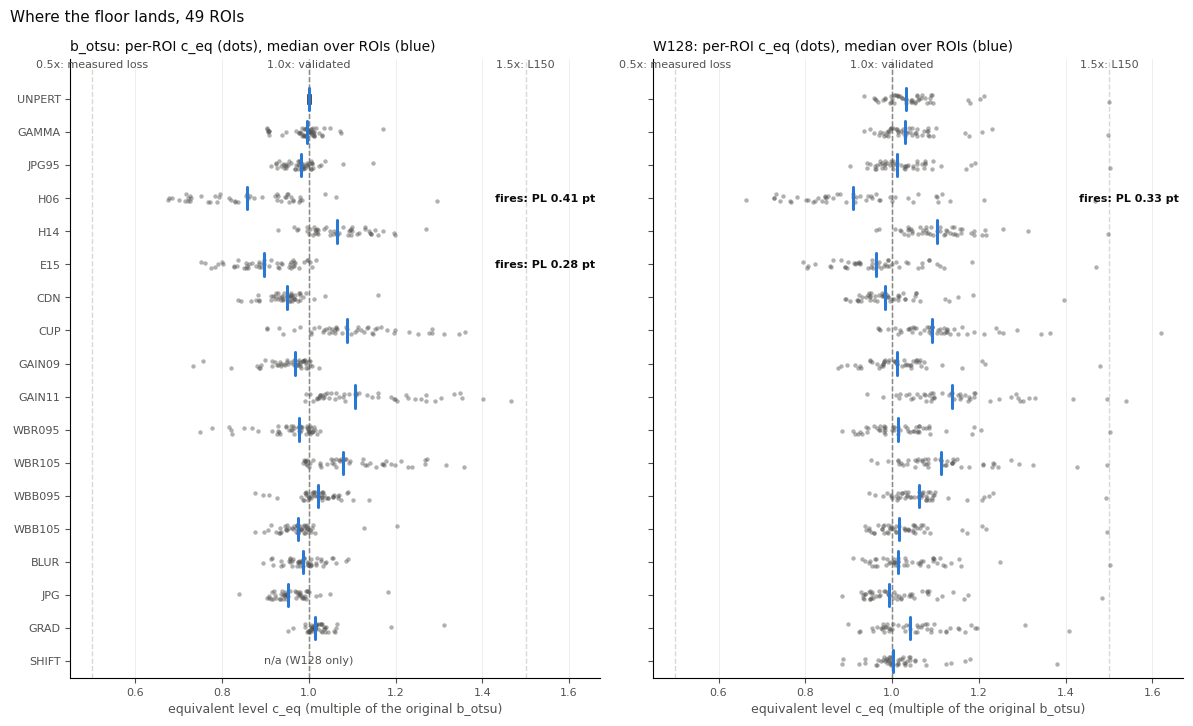

In [10]:
# per-ROI landings of the two decision-set estimators under every variant (embedded only; no file is written)
INK, MUTED, GRID, ACCENT = '#0b0b0b', '#52514e', '#d9d8d4', '#2a78d6'
fig_vars = ['UNPERT'] + CALIBRATION + REALISTIC
fired_set = set(zip(FIRED['var'], FIRED['est']))
per_roi = {(v, e): landings(v, e).groupby('file_name')['c_eq'].median() for v in fig_vars for e in DECISION_EST if not (v == 'SHIFT' and e != 'W128')}
x_lo = min(0.45, min(float(s.min()) for s in per_roi.values()) - 0.05)
x_hi = max(1.6, max(float(s.max()) for s in per_roi.values()) + 0.05)
fig, axes = plt.subplots(1, 2, figsize=(12, 0.32 * len(fig_vars) + 1.6))
for ax, est in zip(axes, DECISION_EST):
    for i, v in enumerate(fig_vars):
        if (v, est) not in per_roi:
            ax.text(1.0, i, 'n/a (W128 only)', ha='center', va='center', fontsize=8, color=MUTED)
            continue
        roi = per_roi[(v, est)]
        jitter = (np.arange(len(roi)) % 7 - 3) * 0.04
        ax.scatter(roi.to_numpy(), i + jitter, s=10, color=MUTED, alpha=0.45, linewidths=0, zorder=2)
        ax.plot([roi.median()] * 2, [i - 0.34, i + 0.34], color=ACCENT, lw=2.2, solid_capstyle='round', zorder=3)
        if (v, est) in fired_set:
            ax.text(x_hi - 0.01, i, f"fires: PL {S.loc[(v, est), 'PL_pts']:.2f} pt", ha='right', va='center', fontsize=8, color=INK, fontweight='bold')
    for x, lab in ((0.5, '0.5x: measured loss'), (1.0, '1.0x: validated'), (1.5, '1.5x: L150')):
        ax.axvline(x, color=GRID if x != 1.0 else MUTED, lw=1, ls='--', zorder=1)
        ax.text(x, -0.9, lab, ha='center', va='bottom', fontsize=8, color=MUTED)
    ax.set_xlim(x_lo, x_hi)
    ax.set_ylim(len(fig_vars) - 0.5, -1.2)
    ax.set_yticks(range(len(fig_vars)))
    ax.set_yticklabels(fig_vars if est == DECISION_EST[0] else [], fontsize=9, color=INK)
    ax.set_title(f'{est}: per-ROI c_eq (dots), median over ROIs (blue)', fontsize=10, color=INK, loc='left')
    ax.set_xlabel('equivalent level c_eq (multiple of the original b_otsu)', fontsize=9, color=MUTED)
    ax.tick_params(colors=MUTED, labelsize=8)
    for s in ('top', 'right'):
        ax.spines[s].set_visible(False)
    ax.grid(axis='x', color=GRID, lw=0.5, alpha=0.6)
fig.suptitle(f"Where the floor lands, {len(RUN_FILES)} ROIs" + (' [SMOKE]' if SMOKE else ''), fontsize=11, color=INK, x=0.01, ha='left')
fig.tight_layout()
plt.show()

## Outputs

In [11]:
# per-ROI values of every variant x estimator (window estimators: the median of the ROI's clicks)
ROI_TABLE = ROWS.groupby(['file_name', 'domain', 'var', 'var_class', 'est'], sort=False).agg(c_eq=('c_eq', 'median'), b=('b', 'median'), n_clicks=('c_eq', 'size'), n_nan=('c_eq', lambda s: int(s.isna().sum()))).reset_index()
decision_rows = [dict(item=k, result=v, detail='') for k, v in {**GATES, **SMOKE_GATES}.items()]
decision_rows += [dict(item=r.item, result=bool(r.ok), detail=f'{r.value:.4f}') for r in CALIB.itertuples()]
decision_rows += [dict(item=f'fires: {r.var} x {r.est}', result=True, detail=f"PL {r.PL_pts:.3f} pt{' (PL)' if r.pl_fires else ''}{' (OVER)' if r.over_fires else ''}; per-ROI median {r.roi_median:.3f}") for r in FIRED.itertuples()]
decision_rows.append(dict(item='Stage B', result=bool(STAGE_B), detail=('runs on ' + ', '.join(STAGE_B) + ' + the null control') if STAGE_B else 'not needed'))
decision_rows.append(dict(item='mode', result=not SMOKE, detail=('SMOKE: not a result; ' if SMOKE else 'FULL; ') + f'N = {N_WORKERS}, wall {WALL:.0f} s'))
DECISION = pd.DataFrame(decision_rows)
adv_result('a1_rank_changes', 'not testable in Stage A', 'stated as a limit; ' + ('Stage B includes GRAD, BLUR and JPG' if STAGE_B else 'reported as untested'))
adv_result('rule_after_pilot', 'the rule (PL >= 0.25 pt, OVER) was applied as fixed in cell 0', 'none')

for name, frame in (('clicks', ROWS), ('roi', ROI_TABLE), ('summary', SUMMARY), ('boxes', BOXES), ('checks', CHECKS), ('decision', DECISION), ('adversarial_log', pd.DataFrame(ADV.values()))):
    frame.to_csv(OUT[name], index=False)
print('written:', *OUT.values(), sep='\n  ')
print(f'total {(time.time() - NB_T0) / 60:.1f} min' + (' [SMOKE RUN: not a result]' if SMOKE else ''))

written:
  ../../results/tm_floor_stress_stageA_49roi_clicks.csv
  ../../results/tm_floor_stress_stageA_49roi_roi.csv
  ../../results/tm_floor_stress_stageA_49roi_summary.csv
  ../../results/tm_floor_stress_stageA_49roi_boxes.csv
  ../../results/tm_floor_stress_stageA_49roi_checks.csv
  ../../results/tm_floor_stress_stageA_49roi_decision.csv
  ../../results/tm_floor_stress_stageA_49roi_adversarial_log.csv
total 3.5 min


## Reading

Written 2026-10-08, after the full run. The run took 3.5 min wall on 11 workers (35 CPU-min; 42 s per ROI under
contention, peak 2.9 GB per worker). The smoke run on 529, 128 and 401 took 2 min, and every gate held there too.
Every number is in-sample on the 49 ROIs.

### Gates: all held

| gate | result |
|---|---|
| 1. configuration and threads | production constants unchanged; skimage 0.24.0; every worker's pools (`openblas:1;openblas:1;openmp:1`) at 1 thread |
| 2. verbatim copies | `refine_template_box` (SHA-1 `21c43a20`), its constants, `roi_floors`, `window_floor` |
| 3. reproduction on this Mac | `b0`: within one bin on 49/49 ROIs, float32-equal on 45; unperturbed W128: within one window bin on 294/294 clicks, float32-equal on 261; 294/294 recorded boxes reproduced |
| 4. `ID` | bit-identical on all 49 ROIs |
| 5. direction | slope 1.003–1.014 (H06), 1.004–1.019 (H14), 0.974–1.011 (E15); H responds more than E on every ROI. Correlation is ≥ 0.998 for the H variants. For E15 its minimum is 0.30 on `410.tiff`, where the Macenko fit is poorest (residual share 0.122 against a median of 0.036). |
| 6. `NULL2` | every floor exactly 2×; every `c_eq` and box unchanged |
| 7. self-consistency | `c_eq` within 7.6e-5 of each ladder level |
| 8. calibration | `NULL2` PL equals the unperturbed PL. GAMMA and JPG95 give PL ≤ 0.081 pt and fire nothing. |
| 9. smoke | N = 3 equals N = 1; the row-blocked channel is bit-identical to the whole-image call |
| Macenko (reported) | angle to `macenko.csv` ≤ 0.32° (h), 0.41° (e); 31 ROIs have some zero-channel pixels, at most 0.92 % |

### Decision: Stage B runs

Three cells fire, all on PL. OVER fires nowhere.

| variant × estimator | PL (P@10 pts) | without the top 2 ROIs | per-ROI median `c_eq` (5th pct, min) | clicks below 0.9 |
|---|---|---|---|---|
| H06 × `b_otsu` | **0.411** | 0.390 | 0.858 (0.692, 0.675) | 59 % |
| H06 × W128 | **0.333** | 0.312 | 0.910 (0.730, 0.663) | 51 % |
| E15 × `b_otsu` | **0.284** | 0.267 | 0.896 (0.779, 0.751) | 53 % |

By the rule fixed in cell 0, **Stage B runs on H06 and E15, plus GRAD, BLUR, JPG and the null control.**

### What it means

1. **A paler hematoxylin stain is the threat, and it is broad.**
   - At H ×0.6, `b_otsu`'s median landing drops to 0.86, and more than half the clicks land below 0.9.
   - Dropping the two largest contributors changes PL by only 0.02 pt. This is not a handful of extreme ROIs.
   - The largest contributors are breast (100, 094, 123), neuroendocrine 401 and lung 233, all near 0.68–0.71. None is
     quantisation-limited.
2. **More eosin also pulls `b_otsu` down; W128 holds.**
   - At E ×1.5, `b_otsu` lands at a median of 0.90 (PL 0.28). W128 lands at 0.96 (PL 0.19, below the threshold).
   - The direction is the one the review found: stroma rises in the H channel, so a smaller tissue share is clipped.
3. **The predicted losses are modest.**
   - PL 0.41 pt is about 12 % of the clip's 3.3-pt gain. Stage B's own decision tolerance is a 1.1-pt shrink.
   - So Stage A predicts that the clip survives these perturbations with a small loss. The screen was built to fire
     early; Stage B measures what happens.
4. **W128 holds better than `b_otsu` under the stain changes that cause undershoot,** but not everywhere.
   - H06: 0.33 against 0.41. E15: 0.19 against 0.28.
   - Part of that is headroom: unperturbed, W128 already sits at a median of 1.033 (5th pct 0.961), while `b_otsu` is at
     1.0 by definition.
   - Under the thickness gradient W128 does worse (PL 0.10 against 0.01): a local window inherits the local thickness,
     while the ROI-wide floor averages it out. It is also slightly worse under H14 and WBB095.
   - Both estimators are far below threshold everywhere except H06, and E15 for `b_otsu`.
   - The tissue-only estimators would not fire at all (H06: TOTSU 0.20, TW128 0.18). But they land higher still
     unperturbed (medians 1.05 and 1.09, up to 1.36 and 1.59), and neither has been searched.
5. **No other variant fires.**
   - The overshoot side (H14, CUP, GAIN11, WBR105) costs nothing.
   - Exposure, white balance and contrast stay below threshold, though GAIN09, WBR095 and CDN pull `b_otsu` to
     0.73–0.84 on their lowest ROIs: PL 0.15 / 0.14 / 0.16.
   - BLUR, JPG and GRAD keep the level (PL ≤ 0.12). Their rank-reshuffling effect goes to Stage B by rule.
   - SHIFT does not drag W128 down (median 1.00, PL 0.08).
6. **For the 1.0× vs 1.5× question.** The measured risk is undershoot under a paler hematoxylin.
   - Under H06, 11/49 ROIs land `b_otsu` below 0.75 (W128: 6/49), though the median is 0.86.
   - The earlier condition for revisiting the level ("`b_otsu` drifting below about 0.75×") is therefore met in the
     tail, not at the median. E15 puts no ROI below 0.75.
   - A higher c would add headroom. How much cannot be read off this table: `c_eq` is a quantile map, so
     `c_eq(1.5·b')` is not 1.5 × `c_eq(b')`.
   - Stage B's 1.5× arm is the direct test.

### Notes for Stage B

- **The refinement box is sensitive to small pixel changes.** Re-run on each variant, it changes on 5–65 % of clicks:
  JPG 65 %, BLUR 62 %, and the near-null JPG95 already 42 %.
  - Almost all changes are one size step (|Δbs| ≤ 2 px on 91–100 %) with the centre moving ≤ 1 px (91–100 %).
  - CUP refuses 24 clicks.
  - Stage B should re-run the refinement on the perturbed image, because that is what the product does, and report
    "clipped, perturbed vs original" with this confound named.
- **Copied zero-channel pixels** under H06 stay dark specks (31 ROIs have some, at most 0.92 % of pixels). Their count
  travels with the H06 searches.
- Stage B's per-worker memory is not yet measured.

### What this cannot answer

- **A1 is untested.** Equal tissue share clipped is assumed to mean the same position on the knee.
- **E15 overstates eosin leak,** because Macenko's E is the pinkest 1 %.
- **Synthesised perturbations at one judged strength** stand in for real labs.
- **In-sample.** These are the 49 ROIs the clip was found on.
- **Out of scope:** precision itself, later loop rounds and chromatin od.